## <span style="color:#1F4E79;">**CDM-Generated Choice Data Fitted with a BTL Model**</span>


This notebook studies model misspecification by generating synthetic
choice observations from a full Context-Dependent Model and fitting a
Bradley--Terry/Luce model to the same data.

The main objective is to determine when a context-independent BTL model
fails to represent choices generated by context-dependent preferences.

In [50]:
# Import libraries and reusable CDM and BTL functions used in this experiment.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from bradley_terry import *
from context_dependent_model import *

In [51]:
SEED = 20260831

NUMBER_OF_ITEMS = 5
NUMBER_OF_OBSERVATIONS = 1_000
CHOICE_SET_SIZES = (2, 3)

TRAIN_FRACTION = 0.8
PARAMETER_SCALE = 0.5

DEVICE = torch.device("cpu")
DTYPE = torch.float64

np.random.seed(SEED)
torch.manual_seed(SEED)
experiment_settings = pd.DataFrame(
    {
        "Setting": [
            "Random seed",
            "Number of items",
            "Number of observations",
            "Choice-set sizes",
            "Training fraction",
            "Parameter scale",
            "PyTorch device",
            "PyTorch dtype",
        ],
        "Value": [
            SEED,
            NUMBER_OF_ITEMS,
            NUMBER_OF_OBSERVATIONS,
            CHOICE_SET_SIZES,
            TRAIN_FRACTION,
            PARAMETER_SCALE,
            DEVICE,
            DTYPE,
        ],
    }
)

experiment_settings

,Setting,Value
0,Random seed,20260831
1,Number of items,5
2,Number of observations,1000
3,Choice-set sizes,"(2, 3)"
4,Training fraction,0.8
5,Parameter scale,0.5
6,PyTorch device,cpu
7,PyTorch dtype,torch.float64


## 2. Generate Choice Data from the Full CDM

In [52]:
# Generate true full-CDM parameters and synthetic choice observations.

true_interactions = generate_cdm_parameters(
    number_of_items=NUMBER_OF_ITEMS,
    parameter_scale=PARAMETER_SCALE,
    random_seed=SEED,
    device=DEVICE,
    dtype=DTYPE,
)

cdm_data = generate_cdm_choice_data(
    interaction_matrix=true_interactions,
    number_of_observations=NUMBER_OF_OBSERVATIONS,
    choice_set_sizes=CHOICE_SET_SIZES,
    random_seed=SEED,
)

In [53]:
# Remove padded entries using the choice mask and create explicit choice observations.

choice_observations = [
    (
        int(chosen_item.item()),
        tuple(
            int(item)
            for item in choice_set[
                choice_mask
            ].detach().cpu().tolist()
        ),
    )
    for choice_set, choice_mask, chosen_item in zip(
        cdm_data.choice_sets,
        cdm_data.choice_mask,
        cdm_data.chosen_items,
    )
]

In [54]:
# Verify the actual choice-set sizes after removing padded entries.

choice_set_size_check = pd.Series(
    [
        len(choice_set)
        for _, choice_set in choice_observations
    ]
).value_counts().sort_index()

print(choice_set_size_check)

print(
    "Contains padding:",
    any(
        -1 in choice_set
        for _, choice_set in choice_observations
    ),
)

2    485
3    515
Name: count, dtype: int64
Contains padding: False


In [55]:
print(type(cdm_data))
print(dir(cdm_data))

<class 'context_dependent_model.simulation.CDMChoiceData'>
['__annotations__', '__class__', '__dataclass_fields__', '__dataclass_params__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__match_args__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'choice_mask', 'choice_sets', 'chosen_items', 'chosen_positions']


In [56]:
# Display the first ten generated choice observations.

choice_observation_preview = pd.DataFrame(
    [
        {
            "Observation": observation_number,
            "Chosen item": chosen_item,
            "Choice set": choice_set,
            "Choice-set size": len(choice_set),
        }
        for observation_number, (
            chosen_item,
            choice_set,
        ) in enumerate(
            choice_observations[:10],
            start=1,
        )
    ]
)

choice_observation_preview

,Observation,Chosen item,Choice set,Choice-set size
0,1,1,"(1, 0, 2)",3
1,2,0,"(2, 0)",2
2,3,4,"(3, 4)",2
3,4,2,"(3, 4, 2)",3
4,5,3,"(3, 0, 2)",3
5,6,2,"(3, 2)",2
6,7,1,"(1, 0)",2
7,8,1,"(1, 3)",2
8,9,4,"(4, 3, 1)",3
9,10,1,"(2, 4, 1)",3


In [57]:
# Summarise the generated interaction matrix and choice observations.

choice_set_size_counts = pd.Series(
    [
        len(choice_set)
        for _, choice_set in choice_observations
    ]
).value_counts()

generation_summary = pd.DataFrame(
    {
        "Quantity": [
            "Interaction-matrix shape",
            "Number of observations",
            "Two-item observations",
            "Three-item observations",
            "Smallest chosen-item index",
            "Largest chosen-item index",
            "Sum of interaction parameters",
        ],
        "Value": [
            tuple(true_interactions.shape),
            len(choice_observations),
            int(choice_set_size_counts.get(2, 0)),
            int(choice_set_size_counts.get(3, 0)),
            min(
                chosen_item
                for chosen_item, _ in choice_observations
            ),
            max(
                chosen_item
                for chosen_item, _ in choice_observations
            ),
            true_interactions.sum().item(),
        ],
    }
)

generation_summary

,Quantity,Value
0,Interaction-matrix shape,"(5, 5)"
1,Number of observations,1000
2,Two-item observations,485
3,Three-item observations,515
4,Smallest chosen-item index,0
5,Largest chosen-item index,4
6,Sum of interaction parameters,0.0


In [58]:
# Count how often each item appears and how often it is chosen.

item_appearance_counts = np.zeros(
    NUMBER_OF_ITEMS,
    dtype=int,
)

item_choice_counts = np.zeros(
    NUMBER_OF_ITEMS,
    dtype=int,
)

for chosen_item, choice_set in choice_observations:
    item_appearance_counts[list(choice_set)] += 1
    item_choice_counts[chosen_item] += 1

item_appearance_summary = pd.DataFrame(
    {
        "Item": np.arange(NUMBER_OF_ITEMS),
        "Number of appearances": item_appearance_counts,
        "Number of times chosen": item_choice_counts,
        "Empirical choice rate": (
            item_choice_counts
            / item_appearance_counts
        ),
    }
)

item_appearance_summary.style.format(
    {
        "Empirical choice rate": "{:.4f}",
    }
)

,Item,Number of appearances,Number of times chosen,Empirical choice rate
0,0,510,120,0.2353
1,1,497,242,0.4869
2,2,506,226,0.4466
3,3,493,153,0.3103
4,4,509,259,0.5088


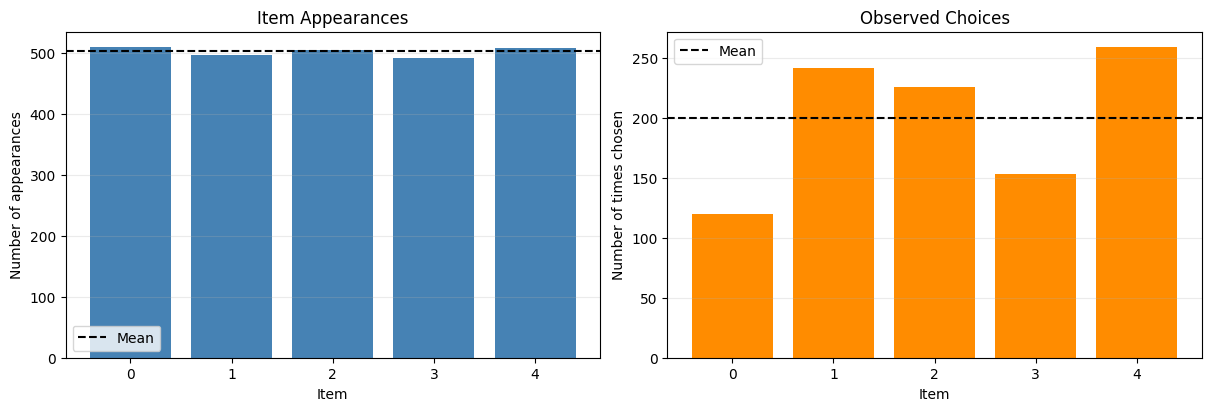

In [59]:
# Plot item appearance and choice counts to inspect sampling coverage.

items = np.arange(NUMBER_OF_ITEMS)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
    constrained_layout=True,
)

axes[0].bar(
    items,
    item_appearance_counts,
    color="steelblue",
)

axes[0].axhline(
    item_appearance_counts.mean(),
    color="black",
    linestyle="--",
    label="Mean",
)

axes[0].set_title("Item Appearances")
axes[0].set_xlabel("Item")
axes[0].set_ylabel("Number of appearances")
axes[0].set_xticks(items)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    items,
    item_choice_counts,
    color="darkorange",
)

axes[1].axhline(
    item_choice_counts.mean(),
    color="black",
    linestyle="--",
    label="Mean",
)

axes[1].set_title("Observed Choices")
axes[1].set_xlabel("Item")
axes[1].set_ylabel("Number of times chosen")
axes[1].set_xticks(items)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.show()

### training and test split

In [60]:
# Split the CDM-generated observations reproducibly into training and test sets.

split_random_generator = np.random.default_rng(
    SEED + 1
)

shuffled_indices = split_random_generator.permutation(
    len(choice_observations)
)

number_of_training_observations = int(
    TRAIN_FRACTION
    * len(choice_observations)
)

training_indices = shuffled_indices[
    :number_of_training_observations
]

test_indices = shuffled_indices[
    number_of_training_observations:
]

training_observations = [
    choice_observations[index]
    for index in training_indices
]

test_observations = [
    choice_observations[index]
    for index in test_indices
]

In [61]:
# Summarise the number and choice-set sizes of the training and test observations.

split_summary = pd.DataFrame(
    {
        "Dataset": [
            "Complete",
            "Training",
            "Test",
        ],
        "Number of observations": [
            len(choice_observations),
            len(training_observations),
            len(test_observations),
        ],
        "Two-item observations": [
            sum(
                len(choice_set) == 2
                for _, choice_set in choice_observations
            ),
            sum(
                len(choice_set) == 2
                for _, choice_set in training_observations
            ),
            sum(
                len(choice_set) == 2
                for _, choice_set in test_observations
            ),
        ],
        "Three-item observations": [
            sum(
                len(choice_set) == 3
                for _, choice_set in choice_observations
            ),
            sum(
                len(choice_set) == 3
                for _, choice_set in training_observations
            ),
            sum(
                len(choice_set) == 3
                for _, choice_set in test_observations
            ),
        ],
    }
)

split_summary

,Dataset,Number of observations,Two-item observations,Three-item observations
0,Complete,1000,485,515
1,Training,800,379,421
2,Test,200,106,94


## 4. Fit the Context-Independent BTL/Luce Model


In [62]:
# Estimate context-independent item parameters from the CDM-generated training data.

estimated_btl_parameters = (
    estimate_top1_parameters_with_choix(
        number_of_items=NUMBER_OF_ITEMS,
        observations=training_observations,
        alpha=0.0,
        maximum_iterations=1_000,
        tolerance=1e-8,
    )
)

In [63]:
# Display the estimated context-independent parameter for each item.

estimated_btl_parameter_table = pd.DataFrame(
    {
        "Item": np.arange(NUMBER_OF_ITEMS),
        "Estimated BTL/Luce parameter": (
            estimated_btl_parameters
        ),
    }
)

estimated_btl_parameter_table.style.format(
    {
        "Estimated BTL/Luce parameter": "{:.4f}",
    }
)

,Item,Estimated BTL/Luce parameter
0,0,-0.6048
1,1,0.3590
2,2,0.2224
3,3,-0.3272
4,4,0.3505


In [64]:
# Evaluate the uniform baseline and fitted BTL/Luce model using average NLL.

uniform_btl_parameters = np.zeros(
    NUMBER_OF_ITEMS
)

uniform_training_nll = (
    average_top1_negative_log_likelihood(
        observations=training_observations,
        parameters=uniform_btl_parameters,
    )
)

estimated_training_nll = (
    average_top1_negative_log_likelihood(
        observations=training_observations,
        parameters=estimated_btl_parameters,
    )
)

uniform_test_nll = (
    average_top1_negative_log_likelihood(
        observations=test_observations,
        parameters=uniform_btl_parameters,
    )
)

estimated_test_nll = (
    average_top1_negative_log_likelihood(
        observations=test_observations,
        parameters=estimated_btl_parameters,
    )
)

In [65]:
# Summarise the training and test NLL of the uniform and fitted models.

btl_nll_summary = pd.DataFrame(
    {
        "Model": [
            "Uniform baseline",
            "Estimated BTL/Luce",
        ],
        "Training NLL": [
            uniform_training_nll,
            estimated_training_nll,
        ],
        "Test NLL": [
            uniform_test_nll,
            estimated_test_nll,
        ],
    }
)

btl_nll_summary.style.format(
    {
        "Training NLL": "{:.4f}",
        "Test NLL": "{:.4f}",
    }
)

,Model,Training NLL,Test NLL
0,Uniform baseline,0.9065,0.8837
1,Estimated BTL/Luce,0.8556,0.8392


In [66]:
# Check how many generated observations contain two and three items.

pd.Series(
    [
        len(choice_set)
        for _, choice_set in choice_observations
    ]
).value_counts().sort_index()

2    485
3    515
Name: count, dtype: int64